# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


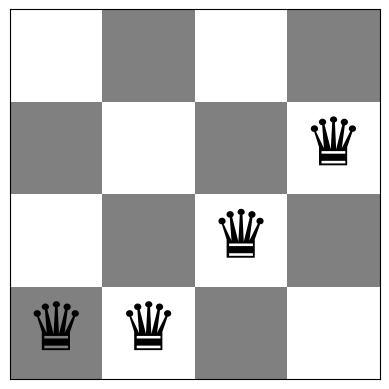

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


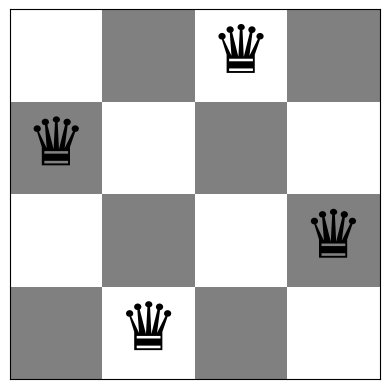

In [4]:
board = [1,3,0,2]
show_board(board)

## Bài 5: Biểu diễn bài toán n quân hậu

**Biểu diễn trạng thái.** `board` là vector n phần tử; `board[i]` là chỉ số hàng (0..n-1) của quân hậu ở cột `i`. Mỗi cột có đúng một quân nên hai quân không bao giờ cùng cột, và không gian tìm kiếm là n^n trạng thái (n = 4: 256; n = 8: 16.777.216) thay vì C(n², n) cách đặt tự do (1.820 và khoảng 4,4·10⁹).

**Hàm mục tiêu.** h(board) = số cặp quân hậu cùng hàng hoặc cùng đường chéo = `conflicts(board)`. Bài toán là min h; lời giải hợp lệ khi h = 0.

**Vì sao `conflicts()` đếm đúng số cặp tấn công.** Hàm đếm số quân trên mỗi hàng, mỗi đường chéo `i + board[i]` và mỗi đường chéo `i - board[i]`, rồi cộng C(k, 2) = k(k-1)/2 cho mỗi nhóm có k quân. Hai quân khác cột không thể vừa cùng hàng vừa cùng đường chéo, và cũng không thể nằm chung trên cả hai loại đường chéo (khi đó chúng trùng cột), nên mỗi cặp tấn công được đếm đúng một lần. h là tổng các số không âm nên **h = 0 khi và chỉ khi không có cặp nào tấn công nhau**.

**Láng giềng.** Một nước đi cục bộ đổi hàng của một quân trong cột của nó, nên mỗi trạng thái có N = n(n-1) láng giềng (n = 4: 12; n = 8: 56).

Ô dưới đây kiểm tra các khẳng định trên bằng cách đối chiếu `conflicts()` với phép đếm trực tiếp theo luật cờ vua.

n=4: 256 bàn cờ, h = số cặp tấn công trên cả 256 bàn; số nghiệm (h=0) = 2: [(1, 3, 0, 2), (2, 0, 3, 1)]
n=8: h = số cặp tấn công trên 20000 bàn ngẫu nhiên; số nghiệm (h=0) = 92 trong 40320 hoán vị
n=4: số trạng thái n^n = 256; số láng giềng n(n-1) = 12; số cách đặt tự do C(n^2, n) = 1,820
n=8: số trạng thái n^n = 16,777,216; số láng giềng n(n-1) = 56; số cách đặt tự do C(n^2, n) = 4,426,165,368
n=4 ngẫu nhiên: [1 0 0 2] h = 3
Board with 3 conflicts.


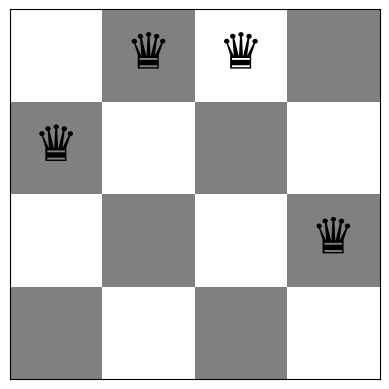

n=8 ngẫu nhiên: [0 7 1 3 7 0 7 1] h = 7
Board with 7 conflicts.


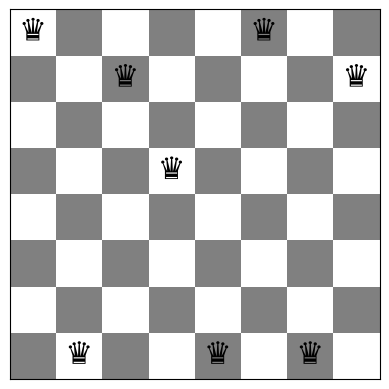

n=8 một nghiệm: (0, 4, 7, 5, 2, 6, 1, 3) h = 0
Board with 0 conflicts.


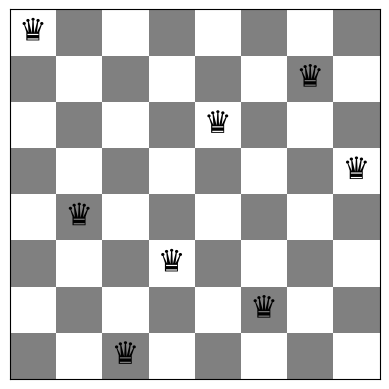

In [5]:
# ===== Bài 5: kiểm tra biểu diễn và hàm mục tiêu h(board) = conflicts(board) =====
import itertools, math
np.random.seed(2024)                       # cố định seed để kết quả tái lập được

def attacking_pairs(board):
    """Đếm cặp quân hậu tấn công nhau TRỰC TIẾP theo luật cờ vua (O(n^2)), dùng để đối chiếu với conflicts()."""
    n = len(board)
    return sum(1 for i in range(n) for j in range(i + 1, n)
               if board[i] == board[j] or abs(board[i] - board[j]) == j - i)   # cùng hàng hoặc cùng đường chéo

# (1) n = 4: kiểm tra TOÀN BỘ 4^4 = 256 bàn cờ
all4 = list(itertools.product(range(4), repeat=4))
assert all(conflicts(b) == attacking_pairs(b) for b in all4)
assert all((conflicts(b) == 0) == (attacking_pairs(b) == 0) for b in all4)
sol4 = [b for b in all4 if conflicts(b) == 0]
print(f"n=4: {len(all4)} bàn cờ, h = số cặp tấn công trên cả {len(all4)} bàn; số nghiệm (h=0) = {len(sol4)}: {sol4}")

# (2) n = 8: 20000 bàn cờ ngẫu nhiên + đếm nghiệm. Nghiệm không có hai quân cùng hàng nên phải là hoán vị của 0..7.
rand8 = [random_board(8) for _ in range(20000)]
assert all(conflicts(b) == attacking_pairs(b) for b in rand8)
perm8 = list(itertools.permutations(range(8)))
sol8 = [p for p in perm8 if conflicts(p) == 0]
assert all(attacking_pairs(p) == 0 for p in sol8)
print(f"n=8: h = số cặp tấn công trên 20000 bàn ngẫu nhiên; số nghiệm (h=0) = {len(sol8)} trong {len(perm8)} hoán vị")

# (3) Quy mô không gian trạng thái và số láng giềng
for n in (4, 8):
    print(f"n={n}: số trạng thái n^n = {n**n:,}; số láng giềng n(n-1) = {n*(n-1)}; số cách đặt tự do C(n^2, n) = {math.comb(n*n, n):,}")

# (4) Hiển thị bàn cờ cùng h(board)
b4 = random_board(4); b8 = random_board(8)
print("n=4 ngẫu nhiên:", b4, "h =", conflicts(b4)); show_board(b4, fontsize=36)
print("n=8 ngẫu nhiên:", b8, "h =", conflicts(b8)); show_board(b8, fontsize=22)
print("n=8 một nghiệm:", sol8[0], "h =", conflicts(sol8[0])); show_board(np.array(sol8[0]), fontsize=22)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

Bàn cờ đầu n=4: [0 2 0 0] h = 4 | n=8: [3 4 6 7 1 7 1 4] h = 7
Steepest n=4: h cuối = 1, số bước = 2, số lần đánh giá h = 37, trạng thái dừng = plateau, bàn cờ = [1 2 0 3]
Steepest n=8: h cuối = 2, số bước = 2, số lần đánh giá h = 169, trạng thái dừng = plateau, bàn cờ = [3 0 6 7 2 7 1 4]
Board with 2 conflicts.


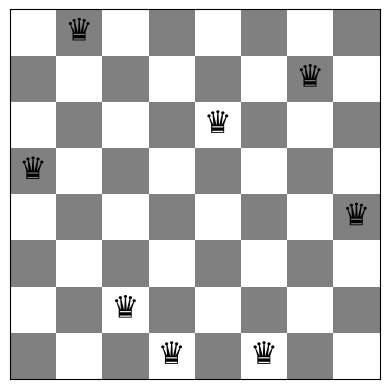

In [6]:
# ===== Task 1: Steepest-ascent Hill Climbing =====
# Mỗi bước: đánh giá tất cả n(n-1) nước đi (đổi hàng của một quân trong cột của nó), chọn nước cho h nhỏ nhất.
# Nếu có nhiều nước cùng tốt nhất thì chọn ngẫu nhiên. Dừng khi h = 0 hoặc khi không còn nước nào làm h giảm nghiêm ngặt.
import time, math

def all_moves(board):
    """Mọi nước đi cục bộ (cột, hàng mới) với hàng mới khác hàng hiện tại: n(n-1) láng giềng."""
    n = len(board)
    return [(c, r) for c in range(n) for r in range(n) if r != board[c]]

def stuck_type(board):
    """Phân loại trạng thái dừng (chỉ phục vụ phân tích, KHÔNG tính vào số lần đánh giá của thuật toán):
    - 'nghiệm': h = 0
    - 'cực trị cục bộ': mọi láng giềng đều có h lớn hơn
    - 'plateau': có láng giềng cùng h nhưng không có láng giềng tốt hơn (chỉ đi ngang được)
    - 'chưa là cực trị': vẫn còn láng giềng tốt hơn (thuật toán dừng sớm, xảy ra ở Task 3)"""
    board = np.array(board).copy(); f = conflicts(board)
    if f == 0: return "nghiệm"
    best = min(_neighbor_values(board))
    return "chưa là cực trị" if best < f else ("plateau" if best == f else "cực trị cục bộ")

def _neighbor_values(board):
    vals = []
    for c, r in all_moves(board):
        old = board[c]; board[c] = r
        vals.append(conflicts(board)); board[c] = old
    return vals

def steepest_ascent(board):
    board = np.array(board).copy()
    f = conflicts(board); evals = 1; history = [f]
    while f > 0:
        best_f, best_moves = f, []
        for c, r in all_moves(board):
            old = board[c]; board[c] = r
            fn = conflicts(board); evals += 1
            board[c] = old                           # hoàn tác để thử nước kế tiếp
            if fn < best_f:
                best_f, best_moves = fn, [(c, r)]
            elif fn == best_f and fn < f:
                best_moves.append((c, r))
        if not best_moves:                           # không có nước cải thiện -> cực trị cục bộ / plateau
            break
        c, r = best_moves[np.random.randint(len(best_moves))]
        board[c] = r; f = best_f; history.append(f)
    return {"board": board, "f": f, "steps": len(history) - 1, "evals": evals, "history": history}

def report(name, res):
    print(f"{name}: h cuối = {res['f']}, số bước = {res['steps']}, số lần đánh giá h = {res['evals']}, "
          f"trạng thái dừng = {stuck_type(res['board'])}, bàn cờ = {res['board']}")

# Chạy thử cùng một bàn cờ đầu cho n = 4 và n = 8
np.random.seed(2024)
start4, start8 = random_board(4), random_board(8)
print("Bàn cờ đầu n=4:", start4, "h =", conflicts(start4), "| n=8:", start8, "h =", conflicts(start8))
r1_4 = steepest_ascent(start4); report("Steepest n=4", r1_4)
r1_8 = steepest_ascent(start8); report("Steepest n=8", r1_8)
show_board(r1_8["board"], fontsize=22)

**Mô tả Task 1 (Steepest-ascent).** Ở mỗi bước, thuật toán đánh giá h cho tất cả N = n(n-1) láng giềng, chọn láng giềng có h nhỏ nhất (nếu có nhiều nước hòa thì chọn ngẫu nhiên) và di chuyển tới đó. Thuật toán dừng khi h = 0 hoặc khi không có láng giềng nào có h nhỏ hơn nghiêm ngặt.

* **Chi phí:** `conflicts()` mất O(n), mỗi bước đánh giá N = O(n²) láng giềng, nên mỗi bước tốn O(n³). Khi thuật toán dừng ở trạng thái kẹt, số lần đánh giá là 1 + N·(số bước + 1): ví dụ n = 8, 2 bước cải thiện cho 1 + 56·3 = 169 lần (đúng với kết quả ở trên), vì vòng cuối vẫn phải duyệt hết N láng giềng để xác nhận không còn nước cải thiện.
* **Dừng ở đâu:** ở cả hai ví dụ trên thuật toán dừng ở trạng thái **plateau** (có láng giềng cùng h nhưng không có láng giềng tốt hơn), không phải cực trị cục bộ chặt. Điều kiện "cải thiện nghiêm ngặt" khiến thuật toán không đi ngang trên plateau.

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [7]:
# ===== Task 2: Inefficient Stochastic Hill Climbing =====
# Giống Task 1 nhưng thay vì chọn nước tốt nhất, liệt kê tất cả nước làm h giảm rồi chọn ngẫu nhiên một nước.
# Vẫn phải đánh giá đủ n(n-1) láng giềng ở mỗi bước nên chi phí mỗi bước bằng Task 1.
def stochastic_all_moves(board):
    board = np.array(board).copy()
    f = conflicts(board); evals = 1; history = [f]
    while f > 0:
        uphill = []
        for c, r in all_moves(board):
            old = board[c]; board[c] = r
            fn = conflicts(board); evals += 1
            board[c] = old
            if fn < f:
                uphill.append((c, r, fn))
        if not uphill:
            break
        c, r, fn = uphill[np.random.randint(len(uphill))]
        board[c] = r; f = fn; history.append(f)
    return {"board": board, "f": f, "steps": len(history) - 1, "evals": evals, "history": history}

np.random.seed(2024)
r2_4 = stochastic_all_moves(start4); report("Stochastic (mọi nước) n=4", r2_4)
r2_8 = stochastic_all_moves(start8); report("Stochastic (mọi nước) n=8", r2_8)

Stochastic (mọi nước) n=4: h cuối = 1, số bước = 2, số lần đánh giá h = 37, trạng thái dừng = plateau, bàn cờ = [1 2 0 3]
Stochastic (mọi nước) n=8: h cuối = 2, số bước = 5, số lần đánh giá h = 337, trạng thái dừng = plateau, bàn cờ = [0 2 6 6 3 7 1 4]


**Mô tả Task 2 (Inefficient Stochastic).** Giống Task 1 nhưng thay vì chọn nước tốt nhất, liệt kê mọi nước làm h giảm rồi chọn ngẫu nhiên một nước. Mỗi bước vẫn phải đánh giá đủ N láng giềng nên chi phí mỗi bước bằng Task 1 (ví dụ n = 8, 5 bước: 1 + 56·6 = 337 lần). Các nước đi nhỏ hơn mức tốt nhất thường làm số bước tăng (ví dụ ở n = 8 trung bình 5,1 bước so với 3,2 của Task 1 ở bảng bên dưới), nên tổng số lần đánh giá lớn hơn.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

Stochastic (ngẫu nhiên) n=4: h cuối = 0, số bước = 3, số lần đánh giá h = 10, trạng thái dừng = nghiệm, bàn cờ = [1 3 0 2]
Stochastic (ngẫu nhiên) n=8: h cuối = 2, số bước = 5, số lần đánh giá h = 260, trạng thái dừng = plateau, bàn cờ = [3 4 6 1 2 7 5 0]


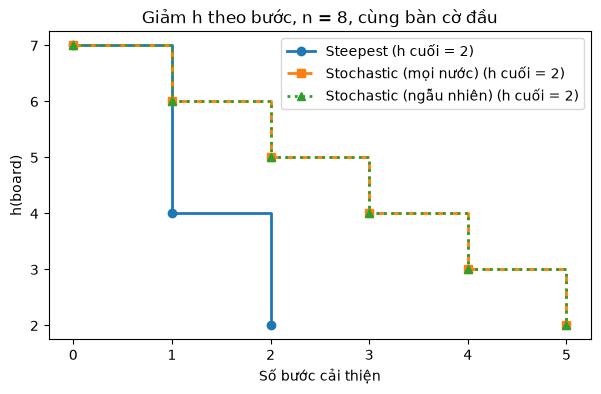

In [8]:
# ===== Task 3: Efficient Stochastic (First-choice) Hill Climbing =====
# Mỗi lần chỉ sinh một láng giềng ngẫu nhiên (chọn cột c, rồi hàng mới r != board[c]), đánh giá h đúng 1 lần,
# chấp nhận nếu h giảm nghiêm ngặt, ngược lại bỏ qua.
#
# Điều kiện dừng (tránh lặp vô hạn): (a) h = 0; (b) x lần thử liên tiếp không cải thiện; (c) tổng số lần thử vượt max_trials.
# Chọn x: có N = n(n-1) láng giềng, rút ngẫu nhiên có hoàn lại. Xác suất một láng giềng cụ thể chưa bị thử sau x lần là
# (1 - 1/N)^x ~ exp(-x/N). Chọn x = ceil(N ln N) cho xác suất bỏ sót ~ 1/N (n=8: N=56, x=226, bỏ sót ~ 1,8%).
def stochastic_efficient(board, patience=None, max_trials=100_000):
    board = np.array(board).copy(); n = len(board); N = n * (n - 1)
    if patience is None:
        patience = math.ceil(N * math.log(N))
    f = conflicts(board); evals = 1; history = [f]
    fails = trials = 0
    while f > 0 and fails < patience and trials < max_trials:
        trials += 1
        c = np.random.randint(n)
        r = np.random.randint(n - 1)
        if r >= board[c]: r += 1                     # hàng mới khác hàng hiện tại
        old = board[c]; board[c] = r
        fn = conflicts(board); evals += 1
        if fn < f:
            f = fn; fails = 0; history.append(f)
        else:
            board[c] = old; fails += 1
    return {"board": board, "f": f, "steps": len(history) - 1, "evals": evals, "history": history}

np.random.seed(2024)
r3_4 = stochastic_efficient(start4); report("Stochastic (ngẫu nhiên) n=4", r3_4)
r3_8 = stochastic_efficient(start8); report("Stochastic (ngẫu nhiên) n=8", r3_8)

# Đường đi của h theo bước trên cùng bàn cờ đầu n = 8
plt.figure(figsize=(7, 4))
for (name, r), ls, mk in zip([("Steepest", r1_8), ("Stochastic (mọi nước)", r2_8), ("Stochastic (ngẫu nhiên)", r3_8)],
                             ["-", "--", ":"], ["o", "s", "^"]):      # khác kiểu đường để thấy cả khi hai đường trùng nhau
    plt.step(range(len(r["history"])), r["history"], where="post", linestyle=ls, linewidth=2, marker=mk,
             label=f"{name} (h cuối = {r['f']})")
plt.xlabel("Số bước cải thiện"); plt.ylabel("h(board)"); plt.title("Giảm h theo bước, n = 8, cùng bàn cờ đầu"); plt.legend(); plt.show()

**Mô tả Task 3 (Efficient Stochastic / First-choice).** Mỗi lần chỉ sinh một láng giềng ngẫu nhiên và đánh giá h đúng một lần; chấp nhận nếu h giảm. Vì không bao giờ đánh giá toàn bộ láng giềng nên phải có điều kiện dừng riêng, gồm ba điều kiện kết hợp: (a) h = 0; (b) **x lần thử liên tiếp không cải thiện**; (c) tổng số lần thử vượt `max_trials` (chốt chặn để chắc chắn không lặp vô hạn).

* **Chọn x.** Rút ngẫu nhiên có hoàn lại từ N láng giềng, xác suất một láng giềng cụ thể chưa bị thử sau x lần là (1 - 1/N)^x ≈ e^(-x/N). x = N cho ≈ 37% bỏ sót (quá nhiều); x = 3N cho ≈ 5%; x = N ln N cho ≈ 1/N (n = 8: ≈ 1,8%, x = 226). Mặc định của code là x = ⌈N ln N⌉. Bảng thực nghiệm bên dưới kiểm chứng điều này.
* **Chi phí:** mỗi lần thử tốn O(n) (một lần gọi `conflicts()`), không phụ thuộc N; nhưng để kết luận kẹt phải trả thêm ít nhất x lần thử.

In [9]:
# ===== Bài 6: đo trên 100 bàn cờ ngẫu nhiên (cùng bộ bàn cờ, cùng seed cho mọi thuật toán) =====
def benchmark(alg, n, runs=100, seed=2024, **kwargs):
    saved = np.random.get_state()
    np.random.seed(seed); boards = [random_board(n) for _ in range(runs)]     # cùng bộ bàn cờ đầu
    np.random.seed(seed + 1)                                                  # dòng ngẫu nhiên của thuật toán
    rows, kinds = [], {"nghiệm": 0, "cực trị cục bộ": 0, "plateau": 0, "chưa là cực trị": 0}
    for b in boards:
        t0 = time.perf_counter(); res = alg(b, **kwargs); dt = (time.perf_counter() - t0) * 1000
        rows.append((res["f"], res["steps"], res["evals"], dt))
        kinds[stuck_type(res["board"])] += 1                                  # phân loại ngoài thời gian đo
    np.random.set_state(saved)
    a = np.array(rows, dtype=float)
    return {"f": a[:, 0].mean(), "ok": (a[:, 0] == 0).mean() * 100, "steps": a[:, 1].mean(),
            "evals": a[:, 2].mean(), "ms": a[:, 3].mean(), **kinds}

print(f"{'Thuật toán':<36}{'n':>3}{'h cuối TB':>10}{'% h=0':>7}{'bước TB':>9}{'#đánh giá TB':>13}{'ms TB':>8}   dừng ở: cực trị / plateau / chưa là cực trị")
for n in (4, 8):
    N = n * (n - 1)
    for name, alg, kw in [("Steepest (Task 1)", steepest_ascent, {}),
                          ("Stochastic - mọi nước (Task 2)", stochastic_all_moves, {}),
                          ("Stochastic - ngẫu nhiên (Task 3)", stochastic_efficient, {})]:
        s = benchmark(alg, n, **kw)
        print(f"{name:<36}{n:>3}{s['f']:>10.2f}{s['ok']:>6.0f}%{s['steps']:>9.2f}{s['evals']:>13.1f}{s['ms']:>8.2f}"
              f"   {s['cực trị cục bộ']} / {s['plateau']} / {s['chưa là cực trị']}")

# Ảnh hưởng của x (điều kiện dừng) trong Task 3
print(f"\n{'Task 3 với x':<26}{'n':>3}{'% h=0':>7}{'#đánh giá TB':>13}{'dừng khi chưa là cực trị':>26}")
for n in (4, 8):
    N = n * (n - 1)
    for label, x in [("x = N", N), ("x = 3N", 3 * N), ("x = N ln N", math.ceil(N * math.log(N))), ("x = 3 N ln N", 3 * math.ceil(N * math.log(N)))]:
        s = benchmark(stochastic_efficient, n, patience=x)
        print(f"{label + f' ({x})':<26}{n:>3}{s['ok']:>6.0f}%{s['evals']:>13.1f}{s['chưa là cực trị']:>26}")

Thuật toán                            n h cuối TB  % h=0  bước TB #đánh giá TB   ms TB   dừng ở: cực trị / plateau / chưa là cực trị
Steepest (Task 1)                     4      0.60    42%     1.67         28.0    0.19   0 / 58 / 0
Stochastic - mọi nước (Task 2)        4      0.86    29%     1.80         31.1    0.20   0 / 71 / 0
Stochastic - ngẫu nhiên (Task 3)      4      0.83    31%     1.85         31.9    0.36   0 / 64 / 5
Steepest (Task 1)                     8      1.21    13%     3.21        229.5    2.36   1 / 86 / 0
Stochastic - mọi nước (Task 2)        8      1.23    23%     5.13        331.4    3.46   3 / 74 / 0
Stochastic - ngẫu nhiên (Task 3)      8      1.22    11%     4.97        275.5    4.37   1 / 87 / 1

Task 3 với x                n  % h=0 #đánh giá TB  dừng khi chưa là cực trị
x = N (12)                  4    21%         16.9                        21
x = 3N (36)                 4    21%         40.7                         4
x = N ln N (30)             4    31%  

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [10]:
# Code and description go here

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [11]:
# Code and description go here

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [12]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [13]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [14]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [15]:
# Code and description go here

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [16]:
# Code and description go here